In [1]:
%pip install transformers torch matplotlib
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import GPT2Tokenizer
import math
import time
import os
import urllib.request
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [2]:
class GPT2Attention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.num_heads = config["n_head"]
        self.head_dim = config["n_embd"] // self.num_heads

        self.c_attn = nn.Linear(config["n_embd"], 3 * config["n_embd"])
        self.c_proj = nn.Linear(config["n_embd"], config["n_embd"])

        self.register_buffer(
            "bias",
            torch.tril(torch.ones(config["n_positions"], config["n_positions"]))
            .view(1, 1, config["n_positions"], config["n_positions"])
        )

    def forward(self, x):
        batch, seq_len, emb = x.shape
        q, k, v = self.c_attn(x).split(emb, dim=2)

        def split_heads(t):
            return t.view(batch, seq_len, self.num_heads, self.head_dim).transpose(1, 2)

        q = split_heads(q)
        k = split_heads(k)
        v = split_heads(v)

        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(self.head_dim))
        att = att.masked_fill(self.bias[:, :, :seq_len, :seq_len] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        out = att @ v

        out = out.transpose(1, 2).contiguous().view(batch, seq_len, emb)
        return self.c_proj(out)

class GPT2MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config["n_embd"], 4 * config["n_embd"])
        self.c_proj = nn.Linear(4 * config["n_embd"], config["n_embd"])

    def forward(self, x):
        return self.c_proj(F.gelu(self.c_fc(x), approximate="tanh"))

class GPT2Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config["n_embd"], eps=config["layer_norm_epsilon"])
        self.attn = GPT2Attention(config)
        self.ln_2 = nn.LayerNorm(config["n_embd"], eps=config["layer_norm_epsilon"])
        self.mlp = GPT2MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class MyGPT2(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.wte = nn.Embedding(config["vocab_size"], config["n_embd"])
        self.wpe = nn.Embedding(config["n_positions"], config["n_embd"])
        self.drop = nn.Dropout(config["embd_pdrop"])
        self.h = nn.ModuleList([GPT2Block(config) for _ in range(config["n_layer"])])
        self.ln_f = nn.LayerNorm(config["n_embd"], eps=config["layer_norm_epsilon"])

    def forward(self, input_ids):
        batch, seq_len = input_ids.shape
        positions = torch.arange(seq_len, device=input_ids.device).unsqueeze(0)
        x = self.drop(self.wte(input_ids) + self.wpe(positions))
        for block in self.h:
            x = block(x)
        x = self.ln_f(x)
        logits = F.linear(x, self.wte.weight)
        return logits

In [3]:
config = {
    "vocab_size": 50257,
    "n_positions": 1024,
    "n_embd": 768,
    "n_layer": 12,
    "n_head": 12,
    "layer_norm_epsilon": 1e-05,
    "embd_pdrop": 0.1,
}

In [4]:
def generate_top_k(model, tokenizer, prompt, max_new_tokens=40, k=50):
    model.eval()
    input_ids = tokenizer.encode(prompt, return_tensors="pt").to(device)
    for _ in range(max_new_tokens):
        with torch.no_grad():
            logits = model(input_ids) if isinstance(model, MyGPT2) else model(input_ids).logits
        next_token_logits = logits[:, -1, :]
        values, _ = torch.topk(next_token_logits, k)
        threshold = values[:, -1].unsqueeze(-1)
        filtered_logits = next_token_logits.masked_fill(next_token_logits < threshold, float("-inf"))
        probs = F.softmax(filtered_logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        input_ids = torch.cat([input_ids, next_token], dim=-1)
        if next_token.item() == tokenizer.eos_token_id:
            break
    return tokenizer.decode(input_ids[0], skip_special_tokens=True)

In [5]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
file_path = "tinyshakespeare.txt"
if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path)

with open(file_path, "r", encoding="utf-8") as f:
    training_text = f.read()

tokens = tokenizer.encode(training_text)
train_data = torch.tensor(tokens, dtype=torch.long)
print("Total characters:", len(training_text))
print("Total tokens:", len(train_data))
print("First 20 tokens:", train_data[:20].tolist())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (338025 > 1024). Running this sequence through the model will result in indexing errors


Total characters: 1115394
Total tokens: 338025
First 20 tokens: [5962, 22307, 25, 198, 8421, 356, 5120, 597, 2252, 11, 3285, 502, 2740, 13, 198, 198, 3237, 25, 198, 5248]


In [6]:
class GPT2Dataset(Dataset):
    def __init__(self, tokens, block_size):
        self.tokens = tokens
        self.block_size = block_size

    def __len__(self):
        return math.ceil((len(self.tokens) - 1) / self.block_size)

    def __getitem__(self, idx):
        start = idx * self.block_size
        end = min(start + self.block_size + 1, len(self.tokens))
        chunk = self.tokens[start:end]
        x = chunk[:-1]
        y = chunk[1:]
        padding = self.block_size - len(x)
        if padding > 0:
            x = F.pad(x, (0, padding), value=tokenizer.eos_token_id)
            y = F.pad(y, (0, padding), value=-100)
        return x, y

In [7]:
block_size = 512
batch_size = 8
train_dataset = GPT2Dataset(train_data, block_size)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=False)
print("Number of batches:", len(train_loader))
x, y = next(iter(train_loader))
print("Input shape:", x.shape)
print("Target shape:", y.shape)

Number of batches: 83
Input shape: torch.Size([8, 512])
Target shape: torch.Size([8, 512])


In [8]:
def initialize_gpt2_weights(model):
    for module in model.modules():
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    n_layer = config["n_layer"]
    residual_std = 0.02 / math.sqrt(2 * n_layer)
    for block in model.h:
        nn.init.normal_(block.attn.c_proj.weight, mean=0.0, std=residual_std)
        nn.init.normal_(block.mlp.c_proj.weight, mean=0.0, std=residual_std)
    return model

In [9]:
model = MyGPT2(config).to(device)
model = initialize_gpt2_weights(model)
model.train()
print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Total parameters: 124,439,808


In [10]:
vocab_size = config["vocab_size"]
n_embd = config["n_embd"]

untied_head = nn.Linear(n_embd, vocab_size, bias=False).to(device)
untied_output_parameters = sum(p.numel() for p in untied_head.parameters())
total_parameters = sum(p.numel() for p in model.parameters())

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", n_embd)
print("Model parameters:", f"{total_parameters:,}")
print("Additional head parameters:", f"{untied_output_parameters:,}")
print("Measured untied total parameters:", f"{total_parameters + untied_output_parameters:,}")
print("Parameters saved via Weight Tying:", f"{untied_output_parameters:,}")

Vocabulary size: 50257
Embedding dimension: 768
Model parameters: 124,439,808
Additional head parameters: 38,597,376
Measured untied total parameters: 163,037,184
Parameters saved via Weight Tying: 38,597,376


In [11]:
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)
with torch.no_grad():
    logits = model(x)
    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)
print("Initial loss:", loss.item())
print("Expected random loss:", math.log(config["vocab_size"]))

Initial loss: 10.94125747680664
Expected random loss: 10.82490511970208


In [12]:
learning_rate = 1e-4
max_steps = 100
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
loss_history = []
train_iter = iter(train_loader)
model.train()

for step in range(1, max_steps + 1):
    try:
        x, y = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        x, y = next(train_iter)
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits = model(x)
    loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if step % 10 == 0 or step == 1:
        print(f"Step {step:03d}/{max_steps} | Loss: {loss.item():.4f}")

Step 001/100 | Loss: 10.9524
Step 010/100 | Loss: 8.7041
Step 020/100 | Loss: 7.7716
Step 030/100 | Loss: 7.1512
Step 040/100 | Loss: 6.7278
Step 050/100 | Loss: 6.4578
Step 060/100 | Loss: 6.2166
Step 070/100 | Loss: 6.1630
Step 080/100 | Loss: 6.0842
Step 090/100 | Loss: 5.8014
Step 100/100 | Loss: 5.7965


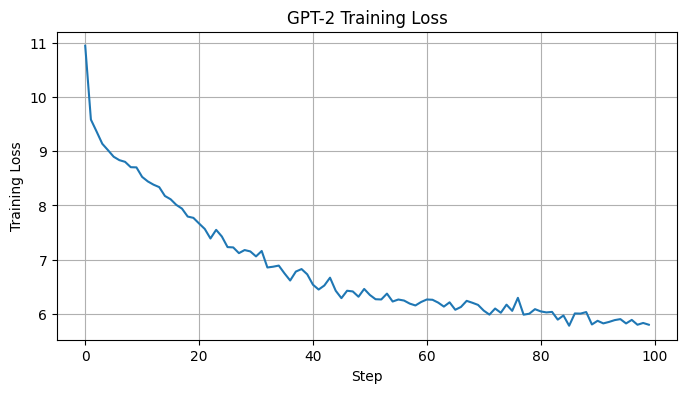

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Step")
plt.ylabel("Training Loss")
plt.title("GPT-2 Training Loss")
plt.grid(True)
plt.show()

In [14]:
print(generate_top_k(model, tokenizer, "Artificial intelligence is", max_new_tokens=40, k=50))
del model, optimizer
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Artificial intelligence is a, so,


And, what of theirIO:

N shall my.


My, and, if this,

YouUS:
That lord:



In [15]:
def benchmark_training(model, x, y, optimizer, steps=20, warmup=5, use_fp16=False):
    model.train()
    measured_steps = 0
    scaler = torch.cuda.amp.GradScaler(enabled=use_fp16)

    for step in range(steps + warmup):
        optimizer.zero_grad(set_to_none=True)
        if use_fp16 and device.type == "cuda":
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(x)
                loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)
            loss.backward()
            optimizer.step()

        if device.type == "cuda":
            torch.cuda.synchronize()
        if step >= warmup:
            if step == warmup:
                start_time = time.perf_counter()
            measured_steps += 1

    if device.type == "cuda":
        torch.cuda.synchronize()
    total_time = time.perf_counter() - start_time
    avg_step_time = total_time / measured_steps
    tokens_per_second = x.numel() / avg_step_time
    return {
        "step_time_ms": avg_step_time * 1000,
        "tokens_per_second": tokens_per_second,
        "loss": loss.item()
    }

In [16]:
x, y = next(iter(train_loader))
x, y = x.to(device), y.to(device)

def sdpa_attention_forward(self, x):
    batch, seq_len, emb = x.shape
    q, k, v = self.c_attn(x).split(emb, dim=2)
    def split_heads(t):
        return t.view(batch, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
    q, k, v = split_heads(q), split_heads(k), split_heads(v)
    out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
    out = out.transpose(1, 2).contiguous().view(batch, seq_len, emb)
    return self.c_proj(out)

manual_attention_forward = GPT2Attention.forward

In [17]:
GPT2Attention.forward = manual_attention_forward
m_base = MyGPT2(config).to(device)
initialize_gpt2_weights(m_base)
opt_base = torch.optim.AdamW(m_base.parameters(), lr=1e-4)
baseline_result = benchmark_training(m_base, x, y, opt_base, use_fp16=False)
del m_base, opt_base; torch.cuda.empty_cache()

tf32_result = None

GPT2Attention.forward = manual_attention_forward
m_fp16 = MyGPT2(config).to(device)
initialize_gpt2_weights(m_fp16)
opt_fp16 = torch.optim.AdamW(m_fp16.parameters(), lr=1e-4)
fp16_result = benchmark_training(m_fp16, x, y, opt_fp16, use_fp16=True)
del m_fp16, opt_fp16; torch.cuda.empty_cache()

GPT2Attention.forward = manual_attention_forward
m_comp_raw = MyGPT2(config).to(device)
initialize_gpt2_weights(m_comp_raw)
m_comp = torch.compile(m_comp_raw)
opt_comp = torch.optim.AdamW(m_comp.parameters(), lr=1e-4)
compiled_result = benchmark_training(m_comp, x, y, opt_comp, use_fp16=True)
del m_comp, m_comp_raw, opt_comp; torch.cuda.empty_cache()

GPT2Attention.forward = sdpa_attention_forward
m_sdpa_raw = MyGPT2(config).to(device)
initialize_gpt2_weights(m_sdpa_raw)
m_sdpa = torch.compile(m_sdpa_raw)
opt_sdpa = torch.optim.AdamW(m_sdpa.parameters(), lr=1e-4)
sdpa_result = benchmark_training(m_sdpa, x, y, opt_sdpa, use_fp16=True)
del m_sdpa, m_sdpa_raw, opt_sdpa; torch.cuda.empty_cache()

padded_config = config.copy()
padded_config["vocab_size"] = 50304
m_pad_raw = MyGPT2(padded_config).to(device)
initialize_gpt2_weights(m_pad_raw)
m_pad = torch.compile(m_pad_raw)
opt_pad = torch.optim.AdamW(m_pad.parameters(), lr=1e-4)
padded_result = benchmark_training(m_pad, x, y, opt_pad, use_fp16=True)
del m_pad, m_pad_raw, opt_pad; torch.cuda.empty_cache()

/tmp/ipykernel_2577/338230260.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_fp16)
W1101 10:34:06.479000 2577 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode
/tmp/ipykernel_2577/338230260.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_fp16)


In [18]:
print("Original vocabulary:", config["vocab_size"])
print("Padded vocabulary: 50304 (Divisible by 128: True)")

results = [
    ("Baseline (Elle Attn, FP32)", baseline_result),
    ("TF32 (Atlandı)", tf32_result),
    ("FP16 (Elle Attn + FP16)", fp16_result),
    ("torch.compile (+ FP16)", compiled_result),
    ("SDPA (+ FP16 + Compile)", sdpa_result),
    ("Vocab 50304 (+ SDPA + FP16 + Compile)", padded_result)
]

baseline_speed = baseline_result["tokens_per_second"]
print(f"{'Optimization':<38} {'Step (ms)':>12} {'Tokens/sec':>15} {'Speedup':>10}")
print("-" * 80)
for name, result in results:
    if result is None:
        print(f"{name:<38} {'Skipped':>12}")
        continue
    speedup = result["tokens_per_second"] / baseline_speed
    print(f"{name:<38} {result['step_time_ms']:>12.3f} {result['tokens_per_second']:>15.2f} {speedup:>9.2f}x")

Original vocabulary: 50257
Padded vocabulary: 50304 (Divisible by 128: True)
Optimization                              Step (ms)      Tokens/sec    Speedup
--------------------------------------------------------------------------------
Baseline (Elle Attn, FP32)                 1024.384         3998.50      1.00x
TF32 (Atlandı)                              Skipped
FP16 (Elle Attn + FP16)                     368.469        11116.28      2.78x
torch.compile (+ FP16)                      271.887        15065.10      3.77x
SDPA (+ FP16 + Compile)                     273.931        14952.68      3.74x
Vocab 50304 (+ SDPA + FP16 + Compile)       229.259        17866.29      4.47x


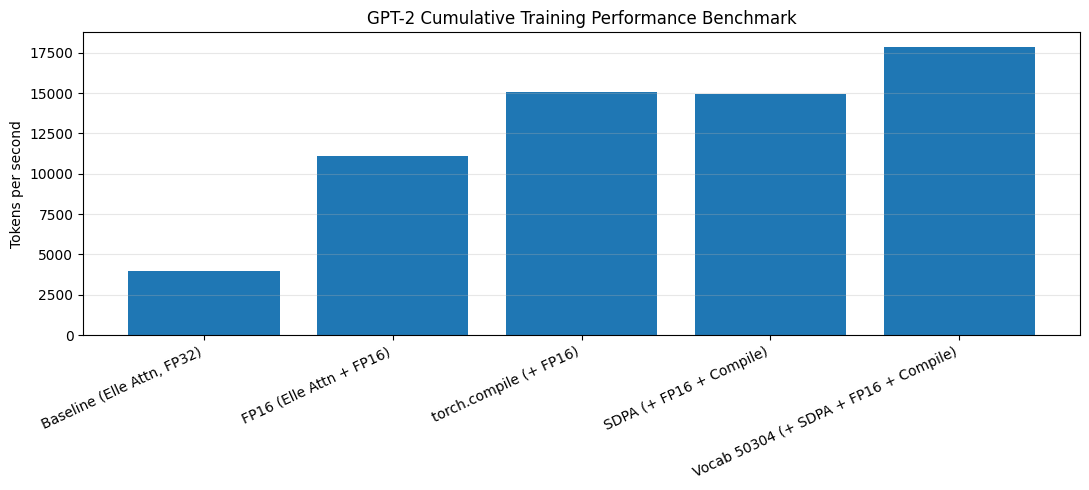

Fastest configuration: Vocab 50304 (+ SDPA + FP16 + Compile)
Highest throughput: 17866.29 tokens/sec (Speedup: 4.47x)


In [19]:
valid_results = [(name, res) for name, res in results if res is not None]
names = [name for name, result in valid_results]
throughputs = [result["tokens_per_second"] for name, result in valid_results]

plt.figure(figsize=(11, 5))
plt.bar(names, throughputs)
plt.ylabel("Tokens per second")
plt.title("GPT-2 Cumulative Training Performance Benchmark")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

fastest_name, fastest_result = max(valid_results, key=lambda item: item[1]["tokens_per_second"])
print("Fastest configuration:", fastest_name)
print(f"Highest throughput: {fastest_result['tokens_per_second']:.2f} tokens/sec (Speedup: {fastest_result['tokens_per_second'] / baseline_speed:.2f}x)")

In [20]:
training_config = config.copy()
training_config["vocab_size"] = 50304
GPT2Attention.forward = sdpa_attention_forward
training_model_raw = MyGPT2(training_config).to(device)
initialize_gpt2_weights(training_model_raw)
training_model = torch.compile(training_model_raw)
print("Görev 3 training_model hazırlandı (SDPA + Compile + Vocab 50304).")

Görev 3 training_model hazırlandı (SDPA + Compile + Vocab 50304).


In [21]:
max_lr = 6e-4
min_lr = max_lr * 0.1
total_steps = 250
warmup_steps = 25

def get_lr(step):
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    if step >= total_steps:
        return min_lr
    decay_ratio = (step - warmup_steps) / (total_steps - warmup_steps)
    coefficient = 0.5 * (1.0 + math.cos(math.pi * decay_ratio))
    return min_lr + coefficient * (max_lr - min_lr)

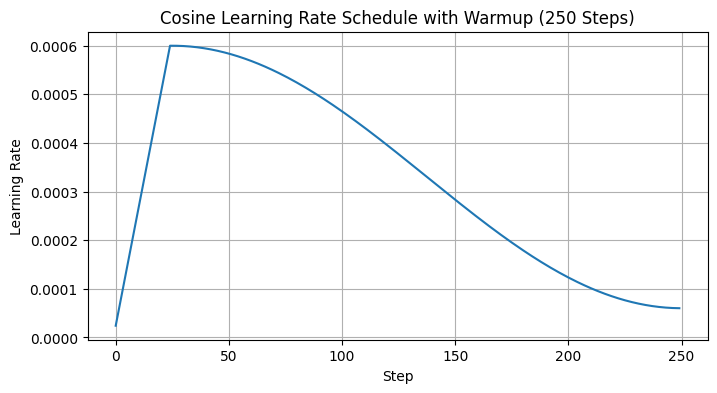

In [22]:
lrs = [get_lr(step) for step in range(total_steps)]
plt.figure(figsize=(8, 4))
plt.plot(lrs)
plt.xlabel("Step")
plt.ylabel("Learning Rate")
plt.title("Cosine Learning Rate Schedule with Warmup (250 Steps)")
plt.grid(True)
plt.show()

In [23]:
decay_params = []
nodecay_params = []
for name, param in training_model.named_parameters():
    if not param.requires_grad:
        continue
    if param.dim() >= 2:
        decay_params.append(param)
    else:
        nodecay_params.append(param)

optim_groups = [
    {"params": decay_params, "weight_decay": 0.1},
    {"params": nodecay_params, "weight_decay": 0.0}
]
print(f"Parameters with weight decay: {sum(p.numel() for p in decay_params):,}")
print(f"Parameters without weight decay: {sum(p.numel() for p in nodecay_params):,}")

Parameters with weight decay: 124,354,560
Parameters without weight decay: 121,344


In [24]:
optimizer = torch.optim.AdamW(optim_groups, lr=max_lr, betas=(0.9, 0.95), eps=1e-8)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambda step: get_lr(step) / max_lr)
scaler = torch.cuda.amp.GradScaler(enabled=True)

/tmp/ipykernel_2577/98165506.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)


In [25]:
max_grad_norm = 1.0
training_losses = []
gradient_norms = []
learning_rates = []

train_iter = iter(train_loader)
training_model.train()

for step in range(1, total_steps + 1):
    try:
        x, y = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        x, y = next(train_iter)

    x, y = x.to(device), y.to(device)
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(device_type="cuda", dtype=torch.float16):
        logits = training_model(x)
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(training_model.parameters(), max_grad_norm)
    scaler.step(optimizer)
    scaler.update()

    current_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()

    training_losses.append(loss.item())
    gradient_norms.append(grad_norm.item())
    learning_rates.append(current_lr)

    if step % 25 == 0 or step == 1:
        print(f"Step {step:03d}/{total_steps} | Loss {loss.item():.4f} | Grad Norm {grad_norm.item():.4f} | LR {current_lr:.6e}")

Step 001/250 | Loss 11.0377 | Grad Norm 28.9671 | LR 2.400000e-05
Step 025/250 | Loss 6.2445 | Grad Norm 1.2208 | LR 6.000000e-04
Step 050/250 | Loss 6.0023 | Grad Norm 1.2391 | LR 5.849816e-04
Step 075/250 | Loss 5.8525 | Grad Norm 1.1785 | LR 5.392350e-04
Step 100/250 | Loss 5.4817 | Grad Norm 0.9146 | LR 4.682516e-04
Step 125/250 | Loss 5.0750 | Grad Norm 1.1180 | LR 3.805930e-04
Step 150/250 | Loss 5.1807 | Grad Norm 0.9190 | LR 2.868321e-04
Step 175/250 | Loss 5.0661 | Grad Norm 0.8014 | LR 1.982779e-04
Step 200/250 | Loss 4.7668 | Grad Norm 0.8228 | LR 1.256113e-04
Step 225/250 | Loss 4.7323 | Grad Norm 0.9120 | LR 7.759707e-05
Step 250/250 | Loss 4.5302 | Grad Norm 0.7779 | LR 6.002632e-05


In [26]:
accum_steps = 4
accum_model_raw = MyGPT2(training_config).to(device)
initialize_gpt2_weights(accum_model_raw)
accum_model = torch.compile(accum_model_raw)

accum_decay = [p for name, p in accum_model.named_parameters() if p.requires_grad and p.dim() >= 2]
accum_nodecay = [p for name, p in accum_model.named_parameters() if p.requires_grad and p.dim() < 2]
accum_groups = [{"params": accum_decay, "weight_decay": 0.1}, {"params": accum_nodecay, "weight_decay": 0.0}]

accum_optimizer = torch.optim.AdamW(accum_groups, lr=max_lr, betas=(0.9, 0.95), eps=1e-8)
accum_scheduler = torch.optim.lr_scheduler.LambdaLR(accum_optimizer, lr_lambda=lambda step: get_lr(step) / max_lr)
accum_scaler = torch.cuda.amp.GradScaler(enabled=True)

/tmp/ipykernel_2577/3088693399.py:12: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  accum_scaler = torch.cuda.amp.GradScaler(enabled=True)


In [27]:
accum_losses = []
accum_grad_norms = []
accum_lrs = []

train_iter = iter(train_loader)
accum_model.train()
accum_optimizer.zero_grad(set_to_none=True)

for step in range(1, total_steps + 1):
    accum_loss_val = 0.0
    for micro_step in range(accum_steps):
        try:
            x, y = next(train_iter)
        except StopIteration:
            train_iter = iter(train_loader)
            x, y = next(train_iter)
        x, y = x.to(device), y.to(device)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = accum_model(x)
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1), ignore_index=-100)
            loss = loss / accum_steps

        accum_scaler.scale(loss).backward()
        accum_loss_val += loss.item() * accum_steps

    accum_scaler.unscale_(accum_optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(accum_model.parameters(), max_grad_norm)
    accum_scaler.step(accum_optimizer)
    accum_scaler.update()

    current_lr = accum_optimizer.param_groups[0]["lr"]
    accum_scheduler.step()
    accum_optimizer.zero_grad(set_to_none=True)

    accum_losses.append(accum_loss_val / accum_steps)
    accum_grad_norms.append(grad_norm.item())
    accum_lrs.append(current_lr)

    if step % 25 == 0 or step == 1:
        print(f"Accum Step {step:03d}/{total_steps} | Loss {accum_losses[-1]:.4f} | Grad Norm {grad_norm.item():.4f} | LR {current_lr:.6e}")

Accum Step 001/250 | Loss 11.0071 | Grad Norm 27.1600 | LR 2.400000e-05
Accum Step 025/250 | Loss 6.1820 | Grad Norm 1.3879 | LR 6.000000e-04
Accum Step 050/250 | Loss 5.7112 | Grad Norm 0.5650 | LR 5.849816e-04
Accum Step 075/250 | Loss 5.3703 | Grad Norm 0.8273 | LR 5.392350e-04
Accum Step 100/250 | Loss 5.1341 | Grad Norm 0.7938 | LR 4.682516e-04
Accum Step 125/250 | Loss 4.9044 | Grad Norm 0.8691 | LR 3.805930e-04
Accum Step 150/250 | Loss 4.5201 | Grad Norm 0.7052 | LR 2.868321e-04
Accum Step 175/250 | Loss 4.4294 | Grad Norm 0.7437 | LR 1.982779e-04
Accum Step 200/250 | Loss 4.1277 | Grad Norm 0.5888 | LR 1.256113e-04
Accum Step 225/250 | Loss 4.1572 | Grad Norm 0.7122 | LR 7.759707e-05
Accum Step 250/250 | Loss 3.9408 | Grad Norm 0.7811 | LR 6.002632e-05


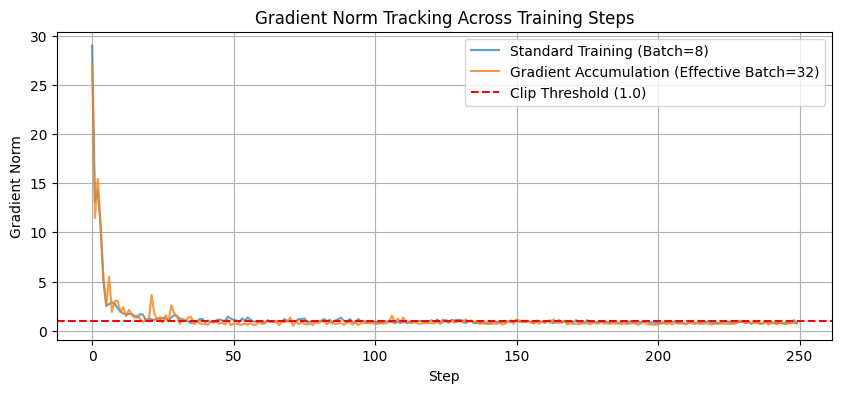

In [28]:
plt.figure(figsize=(10, 4))
plt.plot(gradient_norms, label="Standard Training (Batch=8)", alpha=0.7)
plt.plot(accum_grad_norms, label="Gradient Accumulation (Effective Batch=32)", alpha=0.8)
plt.axhline(y=max_grad_norm, color='r', linestyle='--', label='Clip Threshold (1.0)')
plt.xlabel("Step")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm Tracking Across Training Steps")
plt.legend()
plt.grid(True)
plt.show()

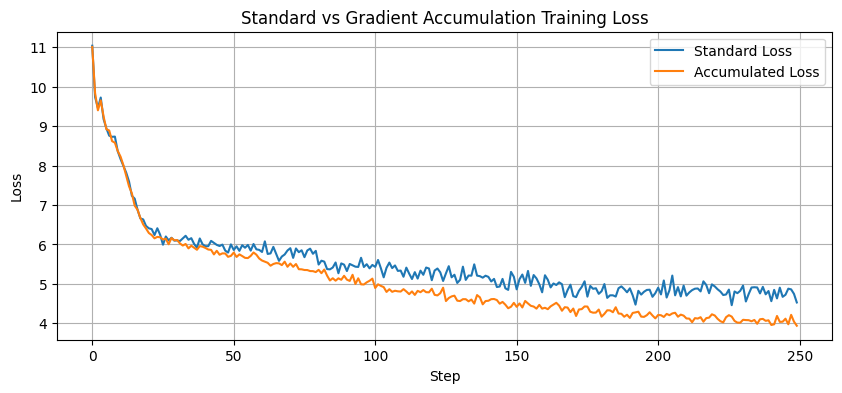

Final Standard Loss: 4.5302
Final Accumulation Loss: 3.9408


In [29]:
plt.figure(figsize=(10, 4))
plt.plot(training_losses, label="Standard Loss")
plt.plot(accum_losses, label="Accumulated Loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Standard vs Gradient Accumulation Training Loss")
plt.legend()
plt.grid(True)
plt.show()

print(f"Final Standard Loss: {training_losses[-1]:.4f}")
print(f"Final Accumulation Loss: {accum_losses[-1]:.4f}")